# GameTheory-14c — Jeux spatiaux : la structure spatiale soutient-elle la coopération ?

**Prérequis** : [06 — Jeux répétés : tournoi d'Axelrod et effet du bruit](GameTheory-06-EvolutionTrust-Python.ipynb).

**La question**. Le carnet 06 (jeux répétés) mesurait l'effet du bruit sur le tournoi d'Axelrod — il en déplace le bas du classement. Plus net encore au duel bien mélangé, où le bruit **détruit** la coopération : un coup inversé fabrique une riposte, la riposte fabrique sa riposte, et la **boule de neige de rancunes** fait chuter la coopération. Nous le mesurons nous-mêmes en §1. La population y est un **mélange homogène** : chaque stratégie rencontre chaque autre au prorata de sa fréquence.

Ce carnet pose la question suivante : **et si les joueurs ne rencontraient que leurs voisins ?** C'est le modèle des **jeux spatiaux** — Axelrod (1981) pour le résultat de cluster, Nowak & May (1992) pour la grille : une grille 2D où chaque joueur joue contre ses 8 voisins, cumule leurs gains, puis **adopte la stratégie du voisin le plus riche**. L'espace crée des **clusters** — et des clusters de coopérateurs se protègent mutuellement d'une manière qu'une population bien mélangée ne permet pas.

**Ce que nous allons mesurer** :
1. un **contrôle bien mélangé** (les stratégies de 06, même jeu de gains) — la coopération y meurt, et le bruit y détruit la coopération au duel ;
2. le **diagramme de phase spatial** : la part finale de coopération dépend-elle de la **proportion** de coopérateurs initiaux, ou de leur **agencement** ? ;
3. le **bruit en espace** : la boule de neige de bruit du §1 survit-elle — ou s'inverse-t-elle — à la structure spatiale ? ;
4. la **taille minimale de cluster** qui survit dans une mer de défauteurs.

*Position dans la série : après 06 (répétés, bien mélangé), avant 15 (coopératif). Python natif + numpy, exécutable sur CPU.*


## 1. Contrôle — la population bien mélangée tue la coopération

Avant d'ajouter l'espace, rétablissons le point de comparaison dans **les mêmes conditions** que le modèle spatial : la même matrice de gains, les mêmes deux stratégies (tit-for-tat vs toujours-défaut), même proportion initiale x₀ de coopérateurs.

Le modèle bien mélangé est celui du **payoff espéré** : chaque stratégie rencontre chaque autre au prorata de sa fréquence dans la population.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

# Matrice de gains du dilemme du prisonnier (même jeu que 06)
GAIN = {('C', 'C'): 3, ('C', 'D'): 0, ('D', 'C'): 5, ('D', 'D'): 1}

# Stratégies (forme « fonction de l'historique des coups de l'adversaire »)
STRATEGIES = {
    'tft':       lambda h: 'C' if not h else h[-1],          # tit-for-tat
    'tft2':      lambda h: 'D' if len(h) >= 2 and 'D' in h[-2:] else 'C',
    'grudger':   lambda h: 'D' if 'D' in h else 'C',
    'allC':      lambda h: 'C',
    'allD':      lambda h: 'D',
}

def dynamique_melangee(part_tft, nb_tours=200, taux_adoption=0.1):
    """Population bien mélangée : x = part de TFT, le reste en AllD.

    Payoff espéré par round (moyenne sur les deux premiers coups de la
    rencontre TFT/AllD : 0 puis 1 pour TFT, 5 puis 1 pour AllD) :
        P(TFT)  = x * 3 + (1 - x) * 0.5
        P(AllD) = x * 3 + (1 - x) * 1.0
    Une fraction `taux_adoption` de la population bascule chaque tour
    vers la stratégie la plus riche.
    """
    x = part_tft
    suite = [x]
    for _ in range(nb_tours):
        p_tft  = x * 3.0 + (1.0 - x) * 0.5
        p_alld = x * 3.0 + (1.0 - x) * 1.0
        if p_tft > p_alld:
            x = min(1.0, x + taux_adoption * (1.0 - x))
        elif p_alld > p_tft:
            x = max(0.0, x - taux_adoption * x)
        suite.append(x)
    return suite

def duel_bruit(p, nb_tours=200, seed=42):
    """Duel tit-for-tat vs tit-for-tat en population bien mélangée, avec bruit.

    `p` : probabilité qu'un coup joué soit inversé (C <-> D). Renvoie la part de
    coups coopératifs réellement joués sur le duel. Sans bruit le duel reste
    coopératif ; un coup inversé désynchronise les deux ripostes et la
    coopération s'effondre — la boule de neige de rancunes.
    """
    rng = random.Random(seed)
    prev_b = 'C'   # dernier coup de B vu par A
    prev_a = 'C'   # dernier coup de A vu par B
    coop = 0
    for t in range(nb_tours):
        a_int = 'C' if t == 0 else prev_b   # TFT : copier le dernier coup de l'adversaire
        b_int = 'C' if t == 0 else prev_a
        a_play = 'D' if rng.random() < p else a_int   # bruit : inversion du coup joué
        b_play = 'D' if rng.random() < p else b_int
        coop += (a_play == 'C') + (b_play == 'C')
        prev_a, prev_b = a_play, b_play   # chacun voit le coup (bruité) de l'autre
    return coop / (2 * nb_tours)

print("contrôle bien mélangé prêt —", len(STRATEGIES), "stratégies disponibles")


contrôle bien mélangé prêt — 5 stratégies disponibles


In [2]:
# Part finale de TFT pour 4 ensemencements initiaux
part_initiales = [0.10, 0.20, 0.30, 0.50]
finales_melange = {}
for x0 in part_initiales:
    suite = dynamique_melangee(x0)
    finales_melange[x0] = suite[-1]
    print(f"x0 = {x0:.2f}  ->  part finale de TFT : {suite[-1]:.4f}")

# Le bruit au duel bien mélangé : tit-for-tat vs lui-même, un coup sur N inversé
bruits_duel = [0.0, 0.01, 0.02, 0.05]
coop_duel = {p: duel_bruit(p) for p in bruits_duel}
print()
for p in bruits_duel:
    print(f"duel TFT-TFT, p = {p:.2f}  ->  part coopérative : {coop_duel[p]:.4f}")


x0 = 0.10  ->  part finale de TFT : 0.0000
x0 = 0.20  ->  part finale de TFT : 0.0000
x0 = 0.30  ->  part finale de TFT : 0.0000
x0 = 0.50  ->  part finale de TFT : 0.0000

duel TFT-TFT, p = 0.00  ->  part coopérative : 1.0000
duel TFT-TFT, p = 0.01  ->  part coopérative : 0.3575
duel TFT-TFT, p = 0.02  ->  part coopérative : 0.1800
duel TFT-TFT, p = 0.05  ->  part coopérative : 0.0150


### Lecture du résultat

**Sans bruit**, quel que soit l'ensemencement initial — de 10 % à 50 % de coopérateurs — la part de tit-for-tat **tend vers zéro**. La cause est arithmétique : en population mélangée, un AllD qui rencontre un TFT y gagne 5 au premier round puis 1 (la riposte), soit 3 de moyenne — exactement son gain contre un AllD, **sans payer le premier round coopératif**. Le défauteur est toujours aussi riche que le coopérateur, et un peu plus : TFT ne peut pas s'y imposer.

**Avec bruit**, le duel tit-for-tat contre lui-même s'effondre : sans inversion il reste coopératif (1,0000), dès p = 0.01 la part coopérative tombe à **0,3575**, et à p = 0.05 elle n'est plus que **0,0150**. Un coup inversé désynchronise les deux ripostes — chacun riposte à la faute de l'autre, la riposte fabrique sa riposte — et la **boule de neige de rancunes** dévore la coopération. C'est ce point de départ, mesuré ici, que la structure spatiale va contester en §3.1.


## 2. Le modèle spatial (Axelrod 1981 ; Nowak & May 1992)

Trois règles, rien d'autre :

1. **Grille 2D en tore** : chaque joueur (i, j) a **8 voisins** (croix + diagonales), les bords s'enroulent ;
2. **Un round** : chaque joueur joue le PD contre chacun de ses 8 voisins (un historique par voisin — la riposte est **locale** : on ne défend que le voisin qui nous a trahi), le gain d'un joueur est la **somme** de ses 8 gains ;
3. **Mise à jour** : chaque joueur **adopte la stratégie de son voisin le plus riche** — son propre gain n'est pas candidat, et à égalité entre voisins c'est le premier dans l'ordre des directions qui l'emporte.

Le bruit est le même que celui mesuré en §1 : avec probabilité p, un coup joué est inversé (C ↔ D). Nous écrivons deux initialisations sur ce même moteur : `simulation_spatiale` disperse les coopérateurs **au hasard**, `cluster_kxk` les regroupe en **un bloc compact** — c'est cette distinction qui porte tout le carnet.


In [3]:
# Les 8 directions du voisinage (tore)
DIRS = [(-1, -1), (-1, 0), (-1, 1),
        ( 0, -1),          ( 0, 1),
        ( 1, -1), ( 1, 0), ( 1, 1)]
IDX = {nom: i for i, nom in enumerate(STRATEGIES)}
FONCS = [STRATEGIES[nom] for nom in STRATEGIES]

def _meilleur(grille, gains, i, j, n):
    """Stratégie du voisin le plus riche ; à égalité, le premier dans l'ordre des directions."""
    meilleur, meilleur_g = grille[i, j], -1
    for d in DIRS:
        g = gains[(i + d[0]) % n, (j + d[1]) % n]
        if g > meilleur_g:
            meilleur, meilleur_g = grille[(i + d[0]) % n, (j + d[1]) % n], g
    return meilleur

def _un_tour(grille, hist, n, p, rng):
    """Un round spatial : joue les 8 voisins, cumule les gains, adopte le plus riche.

    Renvoie la nouvelle grille. `p` : probabilité d'inverser un coup (bruit).
    """
    actions = {}
    for i in range(n):
        for j in range(n):
            s = FONCS[grille[i, j]]
            for d in DIRS:
                a = s(hist[(i, j, d)])
                if rng.random() < p:
                    a = 'D' if a == 'C' else 'C'
                actions[(i, j, d)] = a
    gains = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            tot = 0
            for d in DIRS:
                ni, nj = (i + d[0]) % n, (j + d[1]) % n
                tot += GAIN[(actions[(i, j, d)],
                              actions[(ni, nj, (-d[0], -d[1]))])]
            gains[i, j] = tot
    nouvelle = np.vectorize(lambda i, j: _meilleur(grille, gains, i, j, n))(
        *np.indices((n, n)))
    for (i, j, d) in hist:
        ni, nj = (i + d[0]) % n, (j + d[1]) % n
        hist[(i, j, d)].append(actions[(ni, nj, (-d[0], -d[1]))])
    return nouvelle

def simulation_spatiale(part_init, n=20, nb_tours=300, p=0.0, seed=42,
                        coop='tft', defaut='allD'):
    """Grille où `part_init` des cellules sont `coop`, **placées au hasard**, le reste `defaut`.

    Renvoie (grille_finale, suite) où suite[t] = part de cellules `coop` au tour t.
    """
    rng = random.Random(seed)
    grille = np.full((n, n), IDX[defaut], dtype=int)
    cases = [(i, j) for i in range(n) for j in range(n)]
    for (i, j) in rng.sample(cases, int(round(part_init * n * n))):
        grille[i, j] = IDX[coop]
    hist = {(i, j, d): [] for i in range(n) for j in range(n) for d in DIRS}
    suite = []
    for _ in range(nb_tours):
        suite.append(float(np.mean(grille == IDX[coop])))
        grille = _un_tour(grille, hist, n, p, rng)
    return grille, suite

def cluster_kxk(k, n=20, nb_tours=300, seed=42, p=0.0):
    """Un bloc compact k×k de TFT au centre d'une mer d'AllD ; renvoie (part finale, grille).

    Même moteur que `simulation_spatiale`, seule l'initialisation diffère : les TFT
    forment un bloc continu au lieu d'être dispersés.
    """
    rng = random.Random(seed)
    grille = np.full((n, n), IDX['allD'], dtype=int)
    c = n // 2
    for di in range(k):
        for dj in range(k):
            grille[c - k // 2 + di, c - k // 2 + dj] = IDX['tft']
    hist = {(i, j, d): [] for i in range(n) for j in range(n) for d in DIRS}
    for _ in range(nb_tours):
        grille = _un_tour(grille, hist, n, p, rng)
    return float(np.mean(grille == IDX['tft'])), grille

print("moteur spatial prêt —", len(DIRS), "voisins par cellule")


moteur spatial prêt — 8 voisins par cellule


## 3. Le diagramme de phase : l'agencement décide, pas la proportion

Même nombre de coopérateurs, deux façons de les placer. Le panneau **(a)** disperse x₀ de tit-for-tat **aléatoirement** sur la grille (le contrôle §1, mais en espace) ; le panneau **(b)** les regroupe en **un seul bloc compact** k × k — la proportion totale est la même (k/20)², seul l'agencement change. 300 tours, grille 20 × 20, sans bruit.


dispersé   x0 = 0.10  ->  part finale : 0.0000


dispersé   x0 = 0.20  ->  part finale : 0.0000


dispersé   x0 = 0.30  ->  part finale : 0.0000


dispersé   x0 = 0.50  ->  part finale : 0.0000


bloc  2×2  proportion = 0.0100  ->  part finale : 0.0000


...

bloc  4×4  proportion = 0.0400  ->  part finale : 0.5500


bloc  5×5  proportion = 0.0625  ->  part finale : 0.6500


bloc  6×6  proportion = 0.0900  ->  part finale : 0.7500


bloc  8×8  proportion = 0.1600  ->  part finale : 0.9500


bloc 10×10  proportion = 0.2500  ->  part finale : 1.0000


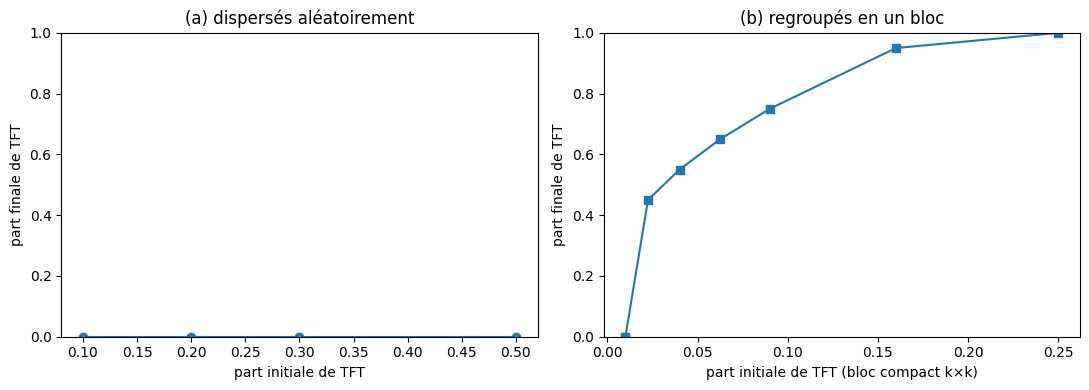

In [4]:
# (a) TFT dispersés aléatoirement — le balayage du contrôle §1, en espace
finales_disparses = {}
for x0 in part_initiales:
    _, suite = simulation_spatiale(x0, n=20)
    finales_disparses[x0] = suite[-1]
    print(f"dispersé   x0 = {x0:.2f}  ->  part finale : {suite[-1]:.4f}")

# (b) TFT regroupés en un bloc compact k×k — même proportion totale (k/20)²
tailles = [2, 3, 4, 5, 6, 8, 10]
prop_blocs, finales_blocs = [], {}
for k in tailles:
    part, _ = cluster_kxk(k, n=20)
    prop = (k / 20) ** 2
    prop_blocs.append(prop)
    finales_blocs[prop] = part
    print(f"bloc {k:>2}×{k}  proportion = {prop:.4f}  ->  part finale : {part:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(part_initiales, [finales_disparses[x] for x in part_initiales], 'o-')
ax[0].set(xlabel='part initiale de TFT', ylabel='part finale de TFT',
          title='(a) dispersés aléatoirement', ylim=(0, 1))
ax[1].plot(prop_blocs, [finales_blocs[p] for p in prop_blocs], 's-')
ax[1].set(xlabel='part initiale de TFT (bloc compact k×k)',
          ylabel='part finale de TFT', title='(b) regroupés en un bloc',
          ylim=(0, 1))
plt.tight_layout()
plt.show()


### Lecture du résultat — le même ensemencement, deux destins

Les deux panneaux disent la même chose en miroir. À **gauche**, la dispersion ne change rien au contrôle : de 10 % à 50 % de tit-for-tat éparpillés, la part finale tombe à **0,0000** à chaque ensemencement — l'espace ne réhabilite pas un coopérateur isolé, car un TFT entouré de défauteurs est envahi tour après tour. À **droite**, le même budget de coopérateurs, simplement **contigu**, donne un résultat radicalement autre : un bloc 3×3 (2,25 % de la grille) stabilise **45 %** de coopération, un 6×6 (9 %) **75 %**, un 10×10 (25 %) **100 %**.

Le point de comparaison qui compte est le croisement des deux lectures : à **9-10 %** de coopérateurs initiaux, dispersés ils s'éteignent à **0**, regroupés en un bloc 6×6 ils portent la grille à **75 %**. C'est exactement la même proportion — ce qui tranche n'est pas **combien** de coopérateurs on sème, mais **comment** on les sème. Le mécanisme est à la frontière : un cluster compact a un **cœur** entouré de coopérateurs (ces cellules ne font jamais face à un défauteur et verrouillent le front), tandis que chaque coopérateur isolé du panneau (a) est une cible. L'espace ne crée pas de la coopération ex nihilo ; il **protège** celle qu'on lui donne, à condition qu'elle se tienne en bloc.


### 3.1 Le bruit, cette fois sur un agencement qui survit

En population mélangée (§1), le bruit est l'arme : un coup inversé fabrique une riposte, la riposte fabrique sa riposte — la **boule de neige de rancunes** qui détruit la coopération en population mélangée. Ici, au lieu de le faire pleuvoir sur une population déjà morte (ce qui ne montrerait rien), nous le posons sur un **bloc qui survit** : un 5×5 (6,25 %, ~65 % sans bruit), p ∈ {0, 0.01, 0.02, 0.05}.


bloc 5×5, p = 0.00  ->  part finale : 0.6500


bloc 5×5, p = 0.01  ->  part finale : 1.0000


bloc 5×5, p = 0.02  ->  part finale : 1.0000


bloc 5×5, p = 0.05  ->  part finale : 1.0000


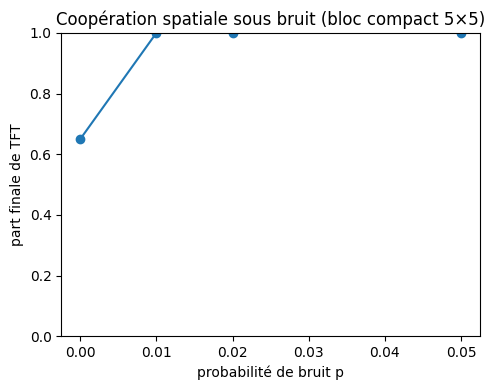

In [5]:
bruits = [0.0, 0.01, 0.02, 0.05]
finales_bruit = {}
for p in bruits:
    part, _ = cluster_kxk(5, n=20, p=p)
    finales_bruit[p] = part
    print(f"bloc 5×5, p = {p:.2f}  ->  part finale : {part:.4f}")

plt.figure(figsize=(5, 4))
plt.plot(bruits, [finales_bruit[p] for p in bruits], 'o-')
plt.xlabel('probabilité de bruit p')
plt.ylabel('part finale de TFT')
plt.title('Coopération spatiale sous bruit (bloc compact 5×5)')
plt.ylim(0, 1)
plt.tight_layout()
plt.show()


### Lecture — la boule de neige, retournée

Le résultat est l'inverse exact du §1, et c'est là que la structure spatiale change le plus. Sans bruit, le bloc 5×5 se stabilise à **65 %** : il ne parvient pas à envahir toute la mer, car les TFT du front qui ouvrent par un C face à un défauteur sont retournés en quelques tours. Dès que le bruit apparaît — p = 0.01, 0.02 puis 0.05 — la part finale ne baisse pas : elle **monte à 100 %**. Le bruit, qui en population mélangée éteint la coopération, la **démocratise** ici.

Le mécanisme inverse la boule de neige de bruit du §1. Là-bas, chaque faute inversée fabriquait une rancune durable dans une population où la riposte se transmettait à tous. Ici, la riposte est **locale** (historique par voisin) : un coup inversé ne contamine que la frontière du cluster, que le cœur compact absorbe. En contrepartie, le bruit **ensemence** la mer de défauteurs — il force parfois un AllD à jouer C, et ce coup coopératif isolé, entouré de TFT gagnants, est adopté par ses voisins et devient une nouvelle graine de cluster. Le bruit devient ainsi un **moteur de colonisation** : il propage la coopération au lieu de la détruire.


## 4. Clusters — la taille minimale qui survit

Le mécanisme proposé par Axelrod (1981) : les coopérateurs ne survivent pas **malgré** l'espace, **à cause** de l'espace — un cluster compact se défend lui-même. Testons-le directement en faisant croître un **bloc k × k** de tit-for-tat posé au centre d'une mer de toujours-défaut (grille 20 × 20, 300 tours) : à partir de quel k le bloc tient-il ?


In [6]:
for k in [1, 2, 3, 4]:
    part, _ = cluster_kxk(k, n=20)
    print(f"bloc {k}×{k}  ->  part finale de TFT : {part:.4f}")


bloc 1×1  ->  part finale de TFT : 0.0000


bloc 2×2  ->  part finale de TFT : 0.0000


bloc 3×3  ->  part finale de TFT : 0.4500


bloc 4×4  ->  part finale de TFT : 0.5500


### Lecture — le seuil de cluster

Le seuil est net et tombe entre 2 et 3 : un **1×1** et un **2×2** s'éteignent (0,0000), un **3×3** stabilise **45 %**, un **4×4** **55 %**. Un coopérateur isolé, ou une paire, n'a pas de cœur : toutes leurs cellules sont au front, et chacune qui ouvre par un C face à un défauteur est retournée avant d'avoir pu se défendre. Dès 3×3, il existe une **cellule centrale** entourée de coopérateurs sur ses 8 côtés — elle ne fait jamais face au front et verrouille le cluster de l'intérieur. Ce cœur, même minuscule, est la condition de survie : c'est la **taille minimale de cluster**, 3×3, en deçà de laquelle l'espace ne protège plus.


## 5. Synthèse — ce que l'espace change (et ce qu'il ne change pas)

L'espace ne **réhabilite** pas la coopération au sens global : le panneau (a) le montre, des coopérateurs **dispersés** s'éteignent à toutes les proportions, exactement comme en population mélangée. Ce que l'espace change, c'est **où** la coopération peut tenir. Trois faits mesurés portent la synthèse :

1. **L'agencement prime sur la proportion.** À proportion égale (9-10 %), dispersé → 0, bloc compact → 75 %. Le diagramme de phase est porté par la **contiguïté**, pas par le nombre.
2. **Il existe un seuil de cluster.** En deçà de 3×3, le bloc n'a pas de cœur et s'éteint ; au-delà, il survit, et plus il est grand, plus la coopération finale est élevée (3×3 → 45 %, 6×6 → 75 %, 10×10 → 100 %).
3. **Le bruit change de signe.** Destructeur en population mélangée (§1, boule de neige de rancunes), il devient **génératif** en espace : localisé par la riposte par-voisin, il ensemence la mer de défauteurs et pousse un cluster survivant à 100 %.

Ce que l'espace **ne change pas** : la matrice de gains du dilemme, le fait qu'un défauteur isolé au milieu de coopérateurs reste temporairement le plus riche, et la fragilité d'un coopérateur sans cluster. La structure spatiale ne rend pas la coopération *toujours* gagnante ; elle en fait un phénomène **local et seuillé** — une question de forme, de taille et de frontières, plutôt que de moyenne sur toute la population.


## 6. Exercices

### Exercice 1 — Une stratégie indulgente en espace

Le carnet 06 montre qu'un tit-for-tat **indulgent** (qui pardonne une faute isolée) résiste mieux au bruit en population mélangée. Réimplétez-le ici : `TitForTatIndulgent` ne défend que si l'adversaire a défecté **deux fois de suite**, puis l'intégrez au dictionnaire `STRATEGIES` sous le nom `'tft_indulgent'`.

```python
def tit_for_tat_indulgent(historique):
    # TODO etudiant : ne retourner 'D' que si les deux derniers coups
    # de l'adversaire sont des 'D'
    print("Exercice a completer")
    return None

# harnais : l'exercice non résolu ne bloque pas le reste du carnet
strategie = tit_for_tat_indulgent(['C', 'C', 'D'])
if strategie is not None:
    print('strategie:', strategie)
else:
    print("(exercice non résolu — le reste du carnet continue)")
```


In [7]:
def tit_for_tat_indulgent(historique):
    print("Exercice a completer")
    # TODO etudiant : ne retourner 'D' que si les deux derniers coups
    # de l'adversaire sont des 'D'
    return None

# harnais : l'exercice non résolu ne bloque pas le reste du carnet
strategie = tit_for_tat_indulgent(['C', 'C', 'D'])
if strategie is not None:
    print('strategie:', strategie)
else:
    print("(exercice non résolu — le reste du carnet continue)")


Exercice a completer
(exercice non résolu — le reste du carnet continue)


### Exercice 2 — Le seuil de cluster par mesure

La mesure du §4 donne un seuil entre k = 2 et k = 3. Generalisez : écrivez `part_finale_cluster(k)` qui renvoie la part finale de TFT pour un bloc k × k, puis affichez le tableau k = 1..6 et repérez le plus petit k qui survit.

```python
def part_finale_cluster(k):
    # TODO etudiant : réutiliser cluster_kxk(k) et renvoyer sa part finale
    print("Exercice a completer")
    return None

# harnais
for k in range(1, 7):
    p = part_finale_cluster(k)
    print(k, '->', p if p is not None else '(à compléter)')
```


In [8]:
def part_finale_cluster(k):
    print("Exercice a completer")
    # TODO etudiant : réutiliser cluster_kxk(k) et renvoyer sa part finale
    return None

# harnais
for k in range(1, 7):
    p = part_finale_cluster(k)
    print(k, '->', p if p is not None else '(à compléter)')


Exercice a completer
1 -> (à compléter)
Exercice a completer
2 -> (à compléter)
Exercice a completer
3 -> (à compléter)
Exercice a completer
4 -> (à compléter)
Exercice a completer
5 -> (à compléter)
Exercice a completer
6 -> (à compléter)


### Exercice 3 — La trajectoire, pas seulement le point final

`simulation_spatiale` renvoie la **trajectoire** complète `suite` (part de TFT à chaque tour). Écrivez `part_cooperation_temps(x0)` qui lance une simulation spatiale et renvoie la trajectoire, puis comparez sur une même figure la trajectoire d'un **bloc** qui survit (via `cluster_kxk`) à celle d'une **dispersion** qui s'éteint : à quel tour les deux destins se séparent-ils ?

```python
def part_cooperation_temps(x0):
    # TODO etudiant : lancer simulation_spatiale(x0) et renvoyer la trajectoire
    print("Exercice a completer")
    return None

# harnais
traj = part_cooperation_temps(0.30)
if traj is not None:
    plt.plot(traj)
    plt.show()
else:
    print("(exercice non résolu — le reste du carnet continue)")
```


In [9]:
def part_cooperation_temps(x0):
    print("Exercice a completer")
    # TODO etudiant : lancer simulation_spatiale(x0) et renvoyer la trajectoire
    return None

# harnais
traj = part_cooperation_temps(0.30)
if traj is not None:
    plt.plot(traj)
    plt.show()
else:
    print("(exercice non résolu — le reste du carnet continue)")


Exercice a completer
(exercice non résolu — le reste du carnet continue)


## Conclusion

Sur la grille, le sort de la coopération ne se joue plus sur une moyenne de population, mais **frontière par frontière**. C'est ce que mesurent les quatre expériences du carnet : un coopérateur **dispersé** s'éteint à toutes les proportions (0,0000), tandis que le **même** nombre de coopérateurs, **contigus** en bloc, stabilise de 45 % (3×3) à 100 % (10×10) ; un cluster **trop petit** (≤ 2×2) n'a pas de cœur et meurt ; et le **bruit**, qui détruisait la coopération en population mélangée, la **propage** ici en ensemencant la mer de défauteurs.

Le modèle spatial ne **réhabilite** donc pas la coopération : il **relocalise** la question. En population mélangée, le sort d'une stratégie se joue sur sa moyenne sur toute la population ; sur la grille, il se joue **frontière par frontière** — et c'est précisément là que le cluster de coopérateurs est fort et le défauteur isolé est faible. La suite de cette ligne — quelles structures locales favorisent la coopération, et quelles règles d'interaction la rendent robuste — mène aux « cinq règles pour l'évolution de la coopération » de Nowak (2006) et aux modèles évolutionnistes que la série ne développe pas.


## Références

- Axelrod, R. (1981). *The Emergence of Cooperation among Egoists*. American Political Science Review, 75(2), 306-318. — le résultat de cluster (théorème 3), moteur du carnet.
- Axelrod, R. & Hamilton, W. D. (1981). *The Evolution of Cooperation*. Science, 211(4489), 1390-1396. — « comment la coopération peut émerger d'un petit cluster ».
- Nowak, M. A. & May, R. M. (1992). *Evolutionary games and spatial chaos*. Nature, 359, 826-829. — le modèle de grille 2D de ce carnet.
- Axelrod, R. (1984). *The Evolution of Cooperation*. Basic Books. — le tournoi repris dans [06 — Jeux répétés](GameTheory-06-EvolutionTrust-Python.ipynb).
- Nowak, M. A. (2006). *Five rules for the evolution of cooperation*. Science, 314(5805), 1560-1563. — la règle « structure spatiale » est l'une des cinq.
- Bonanno, G. (2015). *Game Theory* (manuel open access, 165 exercices corrigés). arXiv:1512.06808 [math.HO], CC BY-NC-ND 4.0. — chapitres sur les jeux répétés.
